In [2]:
import mysql.connector
import pandas as pd
import matplotlib.pyplot as plt

conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="Bhoopendra@99"
)

print("MySQL Connected Successfully!")

cursor = conn.cursor()



MySQL Connected Successfully!


In [3]:
# Read the first sheet of an Excel file
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
df = pd.read_excel("IIOT_Dataset.xlsx")


In [4]:
print(df.head(3))

  Transaction_ID                 Date    Store_Location Region Customer_ID  \
0      TXN-10000  2025-04-13 00:00:00       NY Flagship   East   CUST-1161   
1      TXN-10001           2025-12-15  Atlanta Downtown  South   CUST-1168   
2      TXN-10002           2025-09-28       NY Flagship   East   CUST-1152   

   Gender  Segment    Product_ID Product_Category   Product_Name  \
0  Female  Regular  PROD-ELE-102      Electronics  Wireless Buds   
1    Male    Value  PROD-ELE-100      Electronics     Laptop Pro   
2  Female  Regular  PROD-HOM-100   Home & Kitchen   Air Fryer XL   

   Quantity_Sold  Unit_Cost  Unit_Price  Revenue  Total_Cost  Profit  
0              1         50          99       99          50      49  
1              2        800        1200     2400        1600     800  
2              3         60         120      360         180     180  


In [5]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 149 entries, 0 to 148
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction_ID    149 non-null    str   
 1   Date              149 non-null    object
 2   Store_Location    149 non-null    str   
 3   Region            149 non-null    str   
 4   Customer_ID       149 non-null    str   
 5   Gender            149 non-null    str   
 6   Segment           149 non-null    str   
 7   Product_ID        149 non-null    str   
 8   Product_Category  149 non-null    str   
 9   Product_Name      149 non-null    str   
 10  Quantity_Sold     149 non-null    int64 
 11  Unit_Cost         149 non-null    int64 
 12  Unit_Price        149 non-null    int64 
 13  Revenue           149 non-null    int64 
 14  Total_Cost        149 non-null    int64 
 15  Profit            149 non-null    int64 
dtypes: int64(6), object(1), str(9)
memory usage: 30.7+ KB
None


In [6]:
print(df.describe)

<bound method NDFrame.describe of     Transaction_ID                 Date    Store_Location Region Customer_ID  \
0        TXN-10000  2025-04-13 00:00:00       NY Flagship   East   CUST-1161   
1        TXN-10001           2025-12-15  Atlanta Downtown  South   CUST-1168   
2        TXN-10002           2025-09-28       NY Flagship   East   CUST-1152   
3        TXN-10003           2025-04-17     Seattle Wharf   West   CUST-1178   
4        TXN-10004           2025-03-13       NY Flagship   East   CUST-1040   
..             ...                  ...               ...    ...         ...   
144      TXN-10144           2025-08-10       NY Flagship   East   CUST-1036   
145      TXN-10145           2025-08-19       Miami Beach  South   CUST-1125   
146      TXN-10146           2025-08-25         LA Center   West   CUST-1136   
147      TXN-10147           2025-05-23     Seattle Wharf   West   CUST-1089   
148      TXN-10148           2025-06-20       NY Flagship   East   CUST-1191   

     

In [7]:
print(df.shape)

(149, 16)


In [8]:
print(df.isnull().sum())

Transaction_ID      0
Date                0
Store_Location      0
Region              0
Customer_ID         0
Gender              0
Segment             0
Product_ID          0
Product_Category    0
Product_Name        0
Quantity_Sold       0
Unit_Cost           0
Unit_Price          0
Revenue             0
Total_Cost          0
Profit              0
dtype: int64


In [9]:
print(df.duplicated().sum)

<bound method Series.sum of 0      False
1      False
2      False
3      False
4      False
       ...  
144    False
145    False
146    False
147    False
148    False
Length: 149, dtype: bool>


In [10]:
a_names = df[df['Product_Name'].str.startswith('A', na=False)]
print(a_names)

    Transaction_ID        Date    Store_Location Region Customer_ID  \
2        TXN-10002  2025-09-28       NY Flagship   East   CUST-1152   
7        TXN-10007  2025-04-13         LA Center   West   CUST-1125   
14       TXN-10014  2025-06-01       NY Flagship   East   CUST-1243   
18       TXN-10018  2025-09-15  Atlanta Downtown  South   CUST-1092   
36       TXN-10036  2025-02-20     Boston Common   East   CUST-1029   
39       TXN-10039  2025-09-01         LA Center   West   CUST-1202   
40       TXN-10040  2025-11-16       Detroit Hub  North   CUST-1009   
64       TXN-10064  2025-02-23         LA Center   West   CUST-1121   
66       TXN-10066  2025-09-17       Detroit Hub  North   CUST-1193   
69       TXN-10069  2025-08-06     Boston Common   East   CUST-1148   
93       TXN-10093  2025-10-28     Boston Common   East   CUST-1006   
101      TXN-10101  2025-03-04       Detroit Hub  North   CUST-1102   
105      TXN-10105  2025-10-16     Boston Common   East   CUST-1106   
109   

In [11]:
subset = df[['Product_ID', 'Product_Name', 'Product_Category', 'Quantity_Sold', 'Unit_Cost', 'Unit_Price', 'Revenue']]
print(subset)


       Product_ID    Product_Name Product_Category  Quantity_Sold  Unit_Cost  \
0    PROD-ELE-102   Wireless Buds      Electronics              1         50   
1    PROD-ELE-100      Laptop Pro      Electronics              2        800   
2    PROD-HOM-100    Air Fryer XL   Home & Kitchen              3         60   
3    PROD-ELE-101  Smart Watch v2      Electronics              1        150   
4    PROD-ELE-102   Wireless Buds      Electronics              2         50   
..            ...             ...              ...            ...        ...   
144  PROD-ELE-100      Laptop Pro      Electronics              1        800   
145  PROD-APP-102  Hoodie Comfort          Apparel              4         25   
146  PROD-APP-101   Running Shoes          Apparel              1         45   
147  PROD-BEA-101  Fragrance Luxe           Beauty              2         35   
148  PROD-APP-101   Running Shoes          Apparel              3         45   

     Unit_Price  Revenue  
0           

In [12]:
t_revenue = df.groupby('Product_Category')['Revenue'].mean().reset_index()
print(t_revenue)

  Product_Category     Revenue
0          Apparel  125.540541
1           Beauty  127.275862
2      Electronics  809.976744
3   Home & Kitchen  163.900000


In [13]:
location_region = df.groupby('Store_Location').agg(
    Total_Revenue=('Revenue', 'sum'),
    Average_Revenue=('Revenue', 'mean'),
    Transaction_Count=('Transaction_ID', 'count'),
    Unique_Customer=('Customer_ID', 'nunique')
).reset_index()
print(location_region)

     Store_Location  Total_Revenue  Average_Revenue  Transaction_Count  \
0  Atlanta Downtown          10555       458.913043                 23   
1     Boston Common           5941       297.050000                 20   
2     Chicago Metro           5223       248.714286                 21   
3       Detroit Hub           2302       153.466667                 15   
4         LA Center           3972       220.666667                 18   
5       Miami Beach           5420       416.923077                 13   
6       NY Flagship           7619       476.187500                 16   
7     Seattle Wharf           8689       377.782609                 23   

   Unique_Customer  
0               23  
1               20  
2               20  
3               15  
4               17  
5               11  
6               15  
7               22  


In [16]:
Q1=df['Unit_Price'].quantile(0.25)
Q3=df['Unit_Price'].quantile(0.75)
IQR=Q3-Q1

lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.5*IQR
outliers=df[(df['Unit_Price']< lower_bound) | (df['Unit_Price'] > upper_bound)]

outliers

,Transaction_ID,Date,Store_Location,Region,Customer_ID,Gender,Segment,Product_ID,Product_Category,Product_Name,Quantity_Sold,Unit_Cost,Unit_Price,Revenue,Total_Cost,Profit
1,TXN-10001,2025-12-15,Atlanta Downtown,South,CUST-1168,Male,Value,PROD-ELE-100,Electronics,Laptop Pro,2,800,1200,2400,1600,800
3,TXN-10003,2025-04-17,Seattle Wharf,West,CUST-1178,Female,Premier,PROD-ELE-101,Electronics,Smart Watch v2,1,150,250,250,150,100
19,TXN-10019,2025-12-10,Detroit Hub,North,CUST-1011,Male,Regular,PROD-ELE-101,Electronics,Smart Watch v2,3,150,250,750,450,300
25,TXN-10025,2025-01-22,Atlanta Downtown,South,CUST-1049,Unspecified,Premier,PROD-ELE-101,Electronics,Smart Watch v2,3,150,250,750,450,300
26,TXN-10026,2025-09-10,NY Flagship,East,CUST-1104,Female,Regular,PROD-ELE-101,Electronics,Smart Watch v2,2,150,250,500,300,200
27,TXN-10027,2025-08-24,Boston Common,East,CUST-1211,Female,Regular,PROD-ELE-100,Electronics,Laptop Pro,1,800,1200,1200,800,400
34,TXN-10034,2025-07-09,Atlanta Downtown,South,CUST-1144,Female,Regular,PROD-ELE-101,Electronics,Smart Watch v2,1,150,250,250,150,100
44,TXN-10044,2025-01-21,Boston Common,East,CUST-1219,Female,Regular,PROD-ELE-100,Electronics,Laptop Pro,1,800,1200,1200,800,400
46,TXN-10046,2025-06-16,NY Flagship,East,CUST-1051,Female,Premier,PROD-ELE-100,Electronics,Laptop Pro,3,800,1200,3600,2400,1200
50,TXN-10050,2025-01-14,Atlanta Downtown,South,CUST-1073,Female,Premier,PROD-ELE-100,Electronics,Laptop Pro,2,800,1200,2400,1600,800


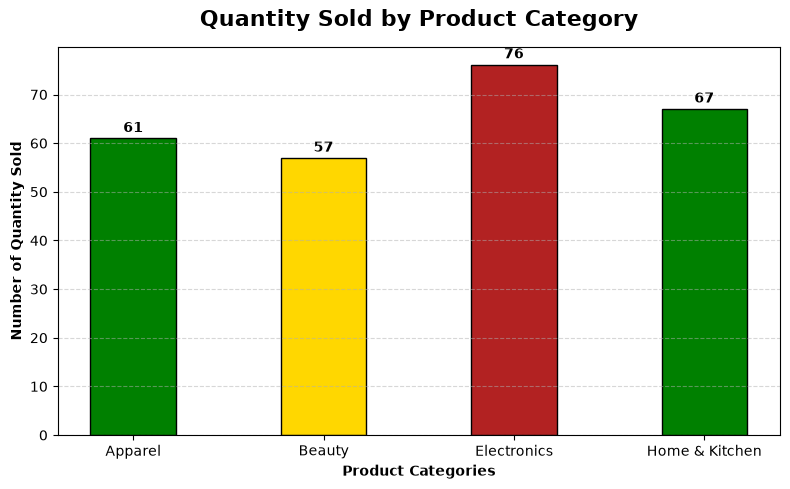

In [86]:
import pandas as pd
import matplotlib.pyplot as plt

# Aggregate Quantity Sold by Category first
cat_df = df.groupby('Product_Category', as_index=False)['Quantity_Sold'].sum()

# Define colors to match the exact number of categories
category_color = ['green', 'gold', 'firebrick']

# Create Bar Chart
plt.figure(figsize=(8, 5))
plt.bar(
    cat_df['Product_Category'], 
    cat_df['Quantity_Sold'], 
    color=category_color[:len(cat_df)], 
    edgecolor='black',
    width=0.45
)

# Add exact value labels on top of bars
for i, val in enumerate(cat_df['Quantity_Sold']):
    plt.text(i, val + (val * 0.01), f'{val:,}', ha='center', va='bottom', fontweight='bold')

plt.title("Quantity Sold by Product Category", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Product Categories", fontsize=10, fontweight="bold")
plt.ylabel("Number of Quantity Sold", fontsize=10, fontweight="bold")
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

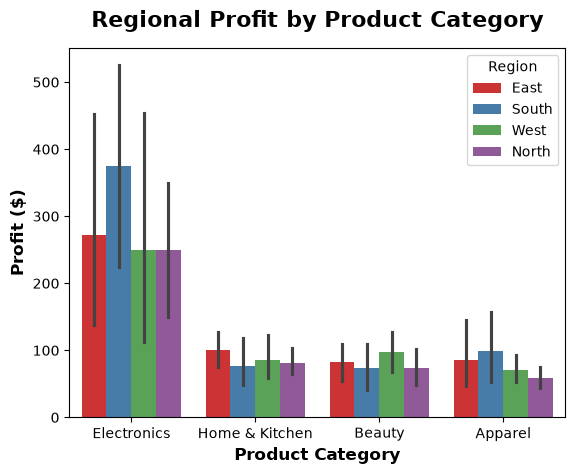

In [15]:
sns.barplot(data=df, y="Profit", x="Product_Category", hue='Region', palette='Set1') 
plt.title("Regional Profit by Product Category", fontsize=16, fontweight="bold", pad=15)

plt.xlabel("Product Category", fontsize=12, fontweight="bold")
plt.ylabel("Profit ($)", fontsize=12, fontweight="bold")
plt.show()


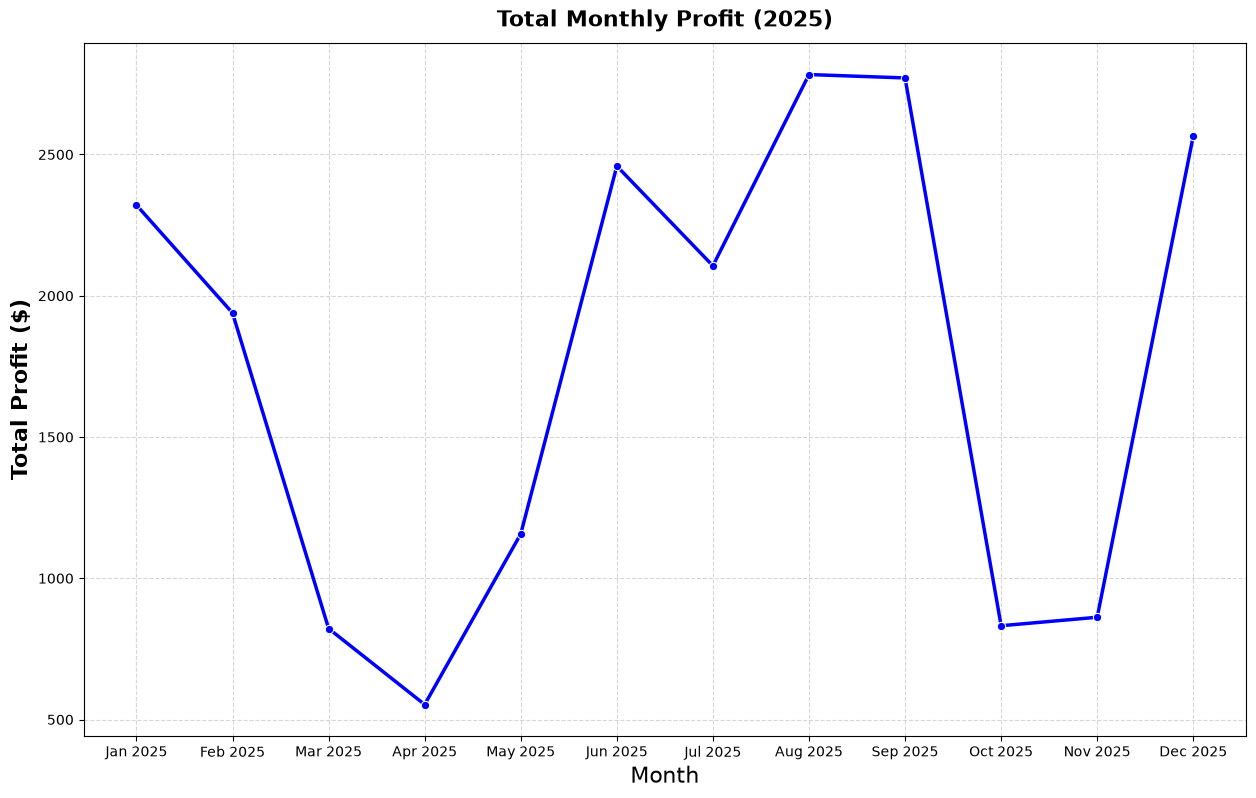

In [55]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_excel("IIOT_Dataset.xlsx")

df['Date'] = pd.to_datetime(df['Date'])

#  Aggregate total profit by month using pd.Grouper (freq='ME' for Month-End)
monthly_df = df.groupby(pd.Grouper(key='Date', freq='ME'))['Profit'].sum().reset_index()

# Optional: Create a formatted month label string for clean x-axis ticks
monthly_df['Month_Year'] = monthly_df['Date'].dt.strftime('%b %Y')

#  Plot using Seaborn
plt.figure(figsize=(15, 9))
sns.lineplot(
    data=monthly_df, 
    x='Month_Year', 
    y='Profit', 
    marker='o', 
    color='blue', 
    linewidth=2.5
)
plt.title('Total Monthly Profit (2025)', fontsize=16, fontweight="bold", pad=12)
plt.xlabel('Month', fontsize=16)
plt.ylabel('Total Profit ($)', fontsize=16, fontweight="bold")
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

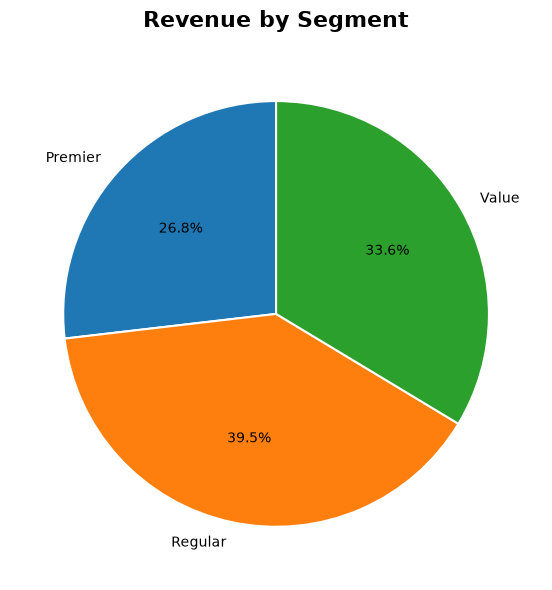

In [71]:
import matplotlib.pyplot as plt

# 1. Summarize Revenue by Segment
segment_df = df.groupby('Segment', as_index=False)['Revenue'].sum()

# 2. Create Pie Chart
plt.figure(figsize=(6, 6))
plt.pie(
    segment_df['Revenue'], 
    labels=segment_df['Segment'], 
    autopct='%1.1f%%', 
    startangle=90,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)

plt.title('Revenue by Segment', fontsize=16, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

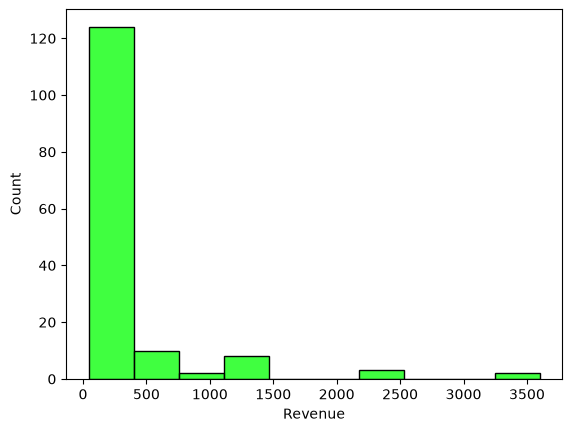

In [17]:
sns.histplot(data=df, x="Revenue", bins=10, color="lime")  
plt.show()


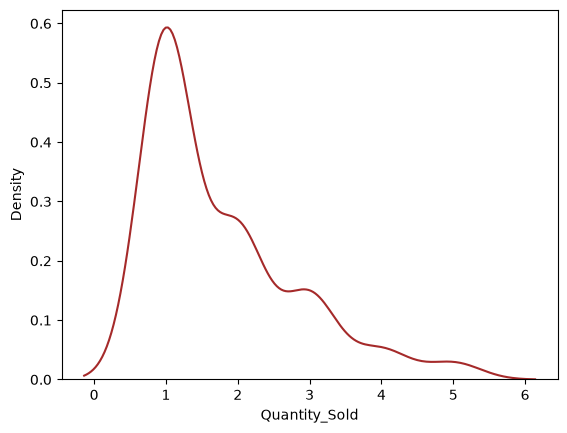

In [18]:
df = pd.read_excel("IIOT_Dataset.xlsx")

sns.kdeplot(df, x="Quantity_Sold", color="Brown")     #kde stands for kernel density estimation
plt.show()

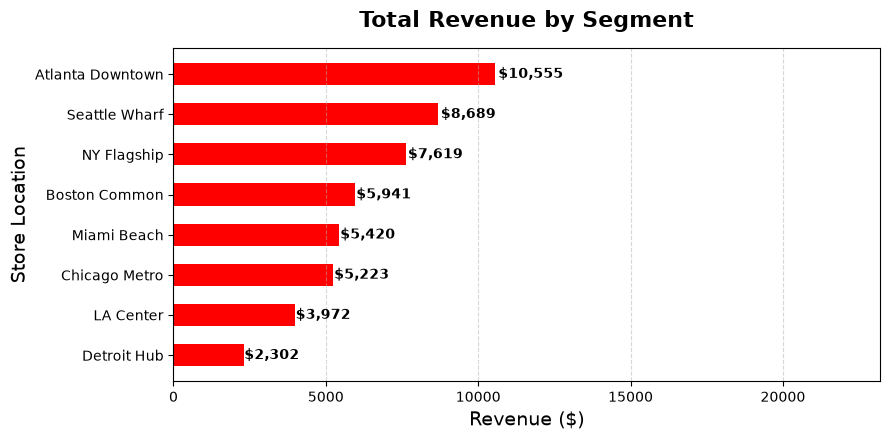

In [82]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Aggregate Revenue by store_location (from df)
store_location_df = df.groupby('Store_Location', as_index=False)['Revenue'].sum()

# 2. Sort values ascending so the top revenue Store location appears at the TOP of the chart
store_location_df = store_location_df.sort_values(by='Revenue', ascending=True)

# 3. Create Horizontal Bar Chart
plt.figure(figsize=(9, 4.5))
bars = plt.barh(store_location_df['Store_Location'], store_location_df['Revenue'], color='red', height=0.55)

# Add value labels at the end of each bar
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + (width * 0.01),          # X-position slightly right of bar tip
        bar.get_y() + bar.get_height()/2, # Y-position centered on bar
        f'${width:,.0f}',                  # Formatted currency string
        va='center', 
        ha='left', 
        fontsize=10, 
        fontweight='bold'
    )

# Formatting
plt.title('Total Revenue by Segment', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Revenue ($)', fontsize=14)
plt.ylabel('Store Location', fontsize=14)
plt.grid(axis='x', linestyle='--', alpha=0.5)

# Add right margin padding so data annotations aren't cut off
plt.xlim(0, segment_df['Revenue'].max() * 1.18)

plt.tight_layout()
plt.show()